In [1]:
import pandas as pd
import numpy as np
import gc
import os
import utils 
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely import wkt
import time
import datetime
#from tqdm import tqdm TODO:Not used ?


In [2]:
# --- 1. SETUP ---
date = "2025-09-07"#A sunday

target_date_obj = pd.to_datetime(date)
data_dir = "data"

# Select GTFS
GTFS_zip_files = ['GTFS_2025-08-13T04-20-01.zip', 'GTFS_2025-08-22T04-20-01.zip', 'GTFS_2025-09-03T04-20-01.zip', 'GTFS_2025-09-04T04-20-01.zip', 'GTFS_2025-09-15T04-20-01.zip']
GTFS_dates = ['2025-08-13', '2025-08-22', '2025-09-03', '2025-09-04', '2025-09-15']

active_GTFS_zip_file = None
for i in range(1, len(GTFS_dates)):
    if GTFS_dates[i] > date:
        active_GTFS_zip_file = GTFS_zip_files[i-1]
        break
if active_GTFS_zip_file is None: active_GTFS_zip_file = GTFS_zip_files[-1]

print(f"Date: {date}")
print(f"GTFS: {active_GTFS_zip_file}")

# Load GTFS
geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file, data_dir)

r=routes[['route_id', 'route_short_name','route_type']]# Keep only the useful columns
r=r.assign(lineId=r['route_short_name'].astype('string')).drop('route_short_name',axis=1)
del routes; gc.collect()
#AUR: Directly changed the dtype in utils.read_gtfs
# *** FIX 1: Force trip_id to String immediately ***
#print("Forcing GTFS trip_id to strings...")
#trips['trip_id'] = trips['trip_id'].astype(str)
#stop_times['trip_id'] = stop_times['trip_id'].astype(str)

Date: 2025-09-07
GTFS: GTFS_2025-09-04T04-20-01.zip
Feed infos: GTFS_2025-09-04T04-20-01.zip
Version: 2_20_20250903_010546
From 2025-09-01 00:00:00 to 2025-09-28 00:00:00
Files read              


0

In [3]:
#%% Get the active stop_times
active_stop_times, active_trips=utils.get_active_stop_times(target_date_obj, trips, stop_times, calendar, calendar_dates)
#%% Convert the time columns of active_stop_times to datetime
active_stop_times=active_stop_times.assign(arrival_datetime=active_stop_times['arrival_time'].str.split(':').apply(lambda x:target_date_obj+datetime.timedelta(hours=int(x[0]), minutes=int(x[1]), seconds=int(x[2]))),
                         departure_datetime=active_stop_times['departure_time'].str.split(':').apply(lambda x:target_date_obj+datetime.timedelta(hours=int(x[0]), minutes=int(x[1]), seconds=int(x[2]))))
#%%Rename
active_trips=active_trips.rename(columns={"direction_id": "direction_mapped"})
#%% Date
active_stop_times=active_stop_times.assign(date=active_stop_times['arrival_datetime'].dt.date)
#%% Fusionne les stop_times actifs et les routes
act=active_trips[['route_id', 'trip_id', 'direction_mapped', 'shape_id']].merge(active_stop_times, on='trip_id', how='outer')
act=act.merge(r, on='route_id', how='outer', indicator=True)
print("Résultat de la fusion entre les stop_times actifs(horaire du jour) et les routes(lignes)")
print(act.drop_duplicates('route_id')['_merge'].value_counts())
s=act.query("_merge=='right_only'")
act=act[act['_merge']!="right_only"]
act=act.drop('_merge',axis=1)
act

Résultat de la fusion entre les stop_times actifs(horaire du jour) et les routes(lignes)
_merge
both          71
right_only    18
left_only      0
Name: count, dtype: int64


,route_id,trip_id,direction_mapped,shape_id,arrival_time,departure_time,stop_id,stop_sequence,pickup_type,drop_off_type,source,arrival_datetime,departure_datetime,date,route_type,lineId
0,1,128004162306378602,True,001m0082,08:35:05,08:35:05,8161,1.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-07 08:35:05,2025-09-07 08:35:05,2025-09-07,1,1
1,1,128004162306378602,True,001m0082,08:36:24,08:36:39,8151,2.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-07 08:36:24,2025-09-07 08:36:39,2025-09-07,1,1
2,1,128004162306378602,True,001m0082,08:37:34,08:37:49,8141,3.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-07 08:37:34,2025-09-07 08:37:49,2025-09-07,1,1
3,1,128004162306378602,True,001m0082,08:38:40,08:38:55,8131,4.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-07 08:38:40,2025-09-07 08:38:55,2025-09-07,1,1
4,1,128004162306378602,True,001m0082,08:40:00,08:40:15,8121,5.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-07 08:40:00,2025-09-07 08:40:15,2025-09-07,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
242813,75,127837456305669600,True,096b0033,24:30:00,24:30:00,2334B,10.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-08 00:30:00,2025-09-08 00:30:00,2025-09-08,3,96
242814,75,127837456305669600,True,096b0033,24:31:13,24:31:13,1708,11.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-08 00:31:13,2025-09-08 00:31:13,2025-09-08,3,96
242815,75,127837456305669600,True,096b0033,24:32:00,24:32:00,1717,12.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-08 00:32:00,2025-09-08 00:32:00,2025-09-08,3,96
242816,75,127837456305669600,True,096b0033,24:33:28,24:33:28,5111B,13.0,False,False,GTFS_2025-09-04T04-20-01.zip,2025-09-08 00:33:28,2025-09-08 00:33:28,2025-09-08,3,96


In [4]:
first_stops = act.loc[act.groupby('trip_id')['stop_sequence'].idxmin()]
first_stops=first_stops.drop(['source','shape_id','arrival_time','departure_time'], axis=1)
first_stops

,route_id,trip_id,direction_mapped,stop_id,stop_sequence,pickup_type,drop_off_type,arrival_datetime,departure_datetime,date,route_type,lineId
47217,10,127425448303021600,False,5104F,1.0,False,True,2025-09-07 05:13:00,2025-09-07 05:13:00,2025-09-07,0,9
47241,10,127425449303021600,False,5104F,1.0,False,True,2025-09-07 05:43:00,2025-09-07 05:43:00,2025-09-07,0,9
47265,10,127425450303021600,False,5104F,1.0,False,True,2025-09-07 06:13:00,2025-09-07 06:13:00,2025-09-07,0,9
47289,10,127425451303021600,False,5104F,1.0,False,True,2025-09-07 07:12:00,2025-09-07 07:12:00,2025-09-07,0,9
47313,10,127425452303021600,False,5104F,1.0,False,True,2025-09-07 07:33:00,2025-09-07 07:33:00,2025-09-07,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...
220891,70,128254257307667602,True,1892,1.0,False,False,2025-09-07 20:41:00,2025-09-07 20:41:00,2025-09-07,3,87
220897,70,128254258307667602,False,1116,1.0,False,False,2025-09-07 20:29:00,2025-09-07 20:29:00,2025-09-07,3,87
220903,70,128254259307667602,True,1892,1.0,False,False,2025-09-07 20:12:00,2025-09-07 20:12:00,2025-09-07,3,87
220909,70,128254260307667602,False,1116,1.0,False,False,2025-09-07 19:59:00,2025-09-07 19:59:00,2025-09-07,3,87


In [5]:
# Load Positions
print("Loading daily Positions...", end="")
positions_today = pd.read_pickle('day_positions('+date+').pkl')

# --- 2. PREPARE POSITIONS ---
if 'timestamp_dt' not in positions_today.columns:
    positions_today['timestamp_dt'] = pd.to_datetime(positions_today['timestamp'], unit='s')
#positions_today=gdf2.copy()#positions_today = gdf2[gdf2['timestamp_dt'].dt.date == target_date_obj].copy()
#print(f"Kept only {len(positions_today)} on {len(gdf2)} positions.")
#del gdf2; gc.collect()
print("Loaded !")

Loading daily Positions...Loaded !


In [6]:
actual_trips_nunique = positions_today.groupby('uuid').nunique()
actual_trips_nunique

,geometry,id,pointId,lineId,direction,distanceFromPoint,timestamp,distance,timestamp_dt
uuid,,,,,,,,,
0001539b-3b71-41c3-84b1-5ba1b9ea8738,25,76,23,1,1,56,97,26,97
00049def-366b-474b-a60f-6e58a3505439,30,71,30,1,1,84,136,35,136
00091d8c-791b-4796-9d19-e6e49b226289,21,38,20,1,1,2,89,22,89
001e54b6-e4d3-4da3-8b31-8f91044c6602,12,30,10,1,1,27,37,13,37
001fc7f2-2be9-45ca-88d1-fb0077e099a2,20,70,18,1,1,79,135,21,135
...,...,...,...,...,...,...,...,...,...
ffed0938-04b0-4af1-9f38-5d899d5d2e0d,12,52,12,1,1,26,56,12,56
ffef25e6-aa22-4a45-95e9-231d13cc4c43,3,29,4,1,1,10,99,3,99
fff59936-9564-4a1d-b3d0-a73663858b96,13,59,13,1,1,36,68,13,68


Les lignes avec le même uuid possède tous les même lineId et direction 

In [7]:
# --- 3. SUMMARIZE ACTUAL TRIPS ---
print("Summarizing actual trips...")
actual_trips_summary = positions_today.groupby('uuid').agg(
    lineId=('lineId', 'first'),
    direction=('direction', 'first'),
    actual_start_time=('timestamp_dt', 'min')
).reset_index()
actual_trips_summary['date'] = actual_trips_summary['actual_start_time'].dt.date
#actual_trips_summary['direction_mapped'] = actual_trips_summary['direction'] - 1
#2 -> False; 1 -> True
actual_trips_summary['direction_mapped']=~(actual_trips_summary['direction'].astype('int64')-1).astype('boolean')
actual_trips_summary['lineId'] = actual_trips_summary['lineId'].astype(str).str.strip()
print(actual_trips_summary)
#del positions_today; gc.collect()

Summarizing actual trips...
                                       uuid lineId  direction  \
0      0001539b-3b71-41c3-84b1-5ba1b9ea8738     59          1   
1      00049def-366b-474b-a60f-6e58a3505439      8          1   
2      00091d8c-791b-4796-9d19-e6e49b226289      1          2   
3      001e54b6-e4d3-4da3-8b31-8f91044c6602     59          2   
4      001fc7f2-2be9-45ca-88d1-fb0077e099a2     89          1   
...                                     ...    ...        ...   
15110  ffed0938-04b0-4af1-9f38-5d899d5d2e0d     42          1   
15111  ffef25e6-aa22-4a45-95e9-231d13cc4c43     47          1   
15112  fff59936-9564-4a1d-b3d0-a73663858b96     14          1   
15113  fff6929a-b2e4-403b-b982-00f311ef44a8      6          2   
15114  fff7d078-6eb7-4f5a-9c73-5c193c517675     38          2   

                  actual_start_time        date  direction_mapped  
0     2025-09-07 05:06:57.852118969  2025-09-07              True  
1     2025-09-07 09:38:39.130531073  2025-09-07        

## Fusion on uuid and trip_id

In [13]:
temp = pd.merge(
    actual_trips_summary,
    first_stops,#gtfs_lookup_final,
    left_on=['lineId', 'direction_mapped'], 
    right_on=['lineId', 'direction_mapped'],
    how='outer',
    indicator=True
)
print(temp.value_counts('_merge'))

_merge
both          1367735
right_only        916
left_only           0
Name: count, dtype: int64


In [8]:
# --- 5. MATCH (Corrected) ---
print("Matching trips...")
candidate_matches = pd.merge(
    actual_trips_summary,
    first_stops,#gtfs_lookup_final,
    left_on=['date', 'lineId', 'direction_mapped'], 
    right_on=['date', 'lineId', 'direction_mapped'],
    how='outer',
    indicator=True
)
candidate_matches=candidate_matches.assign(_merge=candidate_matches['_merge'].astype('string'))
candidate_matches.loc[candidate_matches['_merge']=='right_only','_merge']="Only in GTFS"
candidate_matches.loc[candidate_matches['_merge']=='left_only','_merge']="Only in VehiclePositions"
print(candidate_matches.value_counts('_merge'))

print(f"Candidate matches trip_id type: {candidate_matches['trip_id'].dtype}")

candidate_matches['time_diff_minutes'] = (candidate_matches['actual_start_time'] - candidate_matches['departure_datetime']).dt.total_seconds() / 60
ALLOWABLE_EARLINESS_MIN = -5 
positive_diff_candidates = candidate_matches[candidate_matches['time_diff_minutes'] >= ALLOWABLE_EARLINESS_MIN]
best_matches_idx = positive_diff_candidates.groupby('uuid')['time_diff_minutes'].idxmin()
best_matches = positive_diff_candidates.loc[best_matches_idx]

MATCH_THRESHOLD_MINUTES = 30
final_matches = best_matches[best_matches['time_diff_minutes'] <= MATCH_THRESHOLD_MINUTES]
matched_trips_info = final_matches[['uuid', 'trip_id', 'time_diff_minutes']]

print(f"Match successful for {len(final_matches)} trips on {actual_trips_summary['uuid'].nunique()}.")

# --- 6. SAVE ---
if not matched_trips_info.empty:
    output_filename = f"uuid_trip_matches_{target_date_obj.strftime('%Y-%m-%d')}.pkl"
    matched_trips_info.to_pickle(output_filename)
    print(f"Saved to {output_filename}")
else:
    print("No matches found.")

Matching trips...
_merge
both                        1261002
Only in GTFS                   1253
Only in VehiclePositions        678
Name: count, dtype: int64
Candidate matches trip_id type: string
Match successful for 13402 trips on 15115.
Saved to uuid_trip_matches_2025-09-07.pkl


In [11]:
final_matches[['uuid', 'trip_id']].nunique()

uuid       13402
trip_id     8216
dtype: int64

In [29]:
matched_lines=candidate_matches.query("_merge=='both'").value_counts("lineId")
not_matched_lines=candidate_matches.query("_merge=='Only in GTFS'").value_counts("lineId")
(not_matched_lines/matched_lines).dropna()

Series([], Name: count, dtype: float64)

# Script B ?

In [39]:


date = "2025-09-03"
target_date_obj = pd.to_datetime(date).date()
projected_positions_file = 'All_positions_projected.pkl' 
matches_file = f"uuid_trip_matches_{target_date_obj.strftime('%Y-%m-%d')}.pkl" 
output_file_day = f"positions_matched_{target_date_obj.strftime('%Y-%m-%d')}.pkl"

print("--- Script B (Strict Types) ---")
gdf_projected = pd.read_pickle(projected_positions_file)
uuid_to_trip_map = pd.read_pickle(matches_file)

print("Filtering positions...")
positions_today = gdf_projected[gdf_projected['timestamp_dt'].dt.date == target_date_obj].copy()
del gdf_projected; gc.collect()

print("Merging...")
# Merge
positions_today_matched = positions_today.merge(uuid_to_trip_map, on='uuid', how='left')
positions_today_matched = positions_today_matched.dropna(subset=['trip_id'])

# *** FIX: Force trip_id to string ***
positions_today_matched['trip_id'] = positions_today_matched['trip_id'].astype(str)

print(f"Kept {len(positions_today_matched)} positions.")
print(f"Trip ID sample: {positions_today_matched['trip_id'].iloc[0]} (Should be string, not 1.27e+17)")

positions_today_matched.to_pickle(output_file_day)
print("Saved.")

--- Script B (Strict Types) ---
Filtering positions...
Merging...
Kept 1533465 positions.
Trip ID sample: 127961248306073002 (Should be string, not 1.27e+17)
Saved.


# Compute actual headways

Filtering for arrivals (distance < 50m)...
Found 196565 unique stop arrivals.

--- Headway Statistics ---
count    192510.000000
mean         12.992268
std           8.662958
min           0.000000
25%           7.117873
50%          10.872308
75%          16.197167
max          59.992568
Name: headway_minutes, dtype: float64


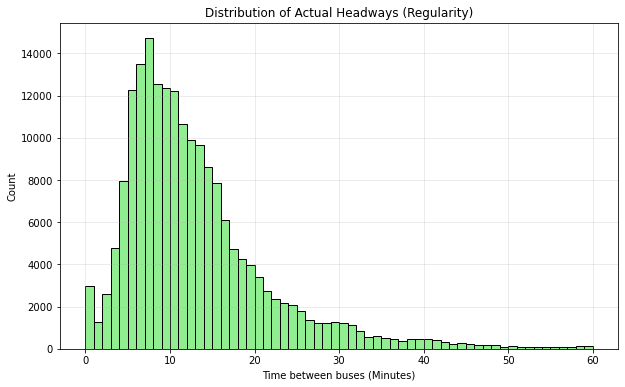

In [45]:
date = "2025-09-03"
input_file = f"positions_matched_{date}.pkl"
df = pd.read_pickle(input_file)


print("Filtering for arrivals (distance < 50m)...")
arrivals = df[df['distanceFromPoint'] < 50].copy()

# We only want the FIRST moment it arrived at the stop (to avoid duplicates while it waits)
# Group by Trip and PointId, take the minimum timestamp
arrivals = arrivals.sort_values('timestamp_dt')
unique_arrivals = arrivals.groupby(['trip_id', 'pointId'])['timestamp_dt'].min().reset_index()

# Add Line and Direction info back (by merging with the trips info)
# (We can merge back with 'df' to get lineId/direction for these trips)
trip_info = df[['trip_id', 'lineId', 'direction']].drop_duplicates()
unique_arrivals = unique_arrivals.merge(trip_info, on='trip_id')

print(f"Found {len(unique_arrivals)} unique stop arrivals.")

# --- 3. Calculate Headway (Regularity) ---
# Sort by Line, Direction, Stop, and Time
unique_arrivals = unique_arrivals.sort_values(['lineId', 'direction', 'pointId', 'timestamp_dt'])

# Calculate the time difference between this bus and the PREVIOUS bus at the same stop
#TODO: You could use .diff()
#I (Aur) don't know if we should use pointId or stop_name
unique_arrivals['prev_arrival_time'] = unique_arrivals.groupby(['lineId', 'direction', 'pointId'])['timestamp_dt'].shift(1)
unique_arrivals['headway_seconds'] = (unique_arrivals['timestamp_dt'] - unique_arrivals['prev_arrival_time']).dt.total_seconds()
unique_arrivals['headway_minutes'] = unique_arrivals['headway_seconds'] / 60

# --- 4. Clean and Visualize ---
# Filter out "First bus of the day" (NaN headway) and huge gaps (> 60 mins)
regularity_data = unique_arrivals[
    (unique_arrivals['headway_minutes'].notna()) &
    (unique_arrivals['headway_minutes'] < 60)
]

print("\n--- Headway Statistics ---")
print(regularity_data['headway_minutes'].describe())

# Visualization: Headway Distribution
plt.figure(figsize=(10, 6))
plt.hist(regularity_data['headway_minutes'], bins=60, color='lightgreen', edgecolor='black')
plt.title('Distribution of Actual Headways (Regularity)')
plt.xlabel('Time between buses (Minutes)')
plt.ylabel('Count')
plt.grid(True, alpha=0.3)
plt.show()

## ...with classification
Classify the lines into frequent and infrequent depending on their median headway (<12 min)

In [46]:
# --- 1. Calculate Headways (The Time Gap) ---
print("Calculating headways...")

# Sort is crucial: We need to compare a bus to the *previous* bus at the *same* stop
# We sort by: Line -> Direction -> Stop (pointId) -> Time
unique_arrivals = unique_arrivals.sort_values(['lineId', 'direction', 'pointId', 'timestamp_dt'])

# Shift(1) gets the previous row's timestamp
unique_arrivals['prev_arrival_time'] = unique_arrivals.groupby(['lineId', 'direction', 'pointId'])['timestamp_dt'].shift(1)

# Calculate difference
unique_arrivals['headway_seconds'] = (unique_arrivals['timestamp_dt'] - unique_arrivals['prev_arrival_time']).dt.total_seconds()
unique_arrivals['headway_minutes'] = unique_arrivals['headway_seconds'] / 60

# Filter: Remove first bus of the day (NaN) and huge gaps (> 60 min, likely missing data)
df_reg = unique_arrivals[
    (unique_arrivals['headway_minutes'].notna()) & 
    (unique_arrivals['headway_minutes'] < 60)
].copy()

print(f"Valid headway measurements: {len(df_reg)}")

# --- 2. Task 1: Classify Lines (Frequent vs. Punctuality) ---
# Project Rule: "headway is lower than 12min" = Regularity 
print("\n--- Task 1: Line Classification ---")

# Calculate Median Headway per line
line_stats = df_reg.groupby('lineId')['headway_minutes'].median().sort_values().reset_index()
line_stats.columns = ['lineId', 'median_headway']

# Split the lines
frequent_lines = line_stats[line_stats['median_headway'] <= 12]['lineId'].tolist()
punctuality_lines = line_stats[line_stats['median_headway'] > 12]['lineId'].tolist()

print(f"Total Lines: {len(line_stats)}")
print(f"Frequent Lines (Analyze Regularity): {len(frequent_lines)}")
print(f"Standard Lines (Analyze Punctuality): {len(punctuality_lines)}")
print(f"Sample Frequent Lines: {frequent_lines[:5]}")


# --- 3. Task 3: Calculate EWT (Excess Waiting Time) ---
# Metric for Regularity [cite: 22]
print("\n--- Task 3: Calculating EWT for Frequent Lines ---")

def calculate_ewt_metrics(group):
    h = group['headway_minutes']
    #TODO: retrieve the schedule headway sh
    
    # Scheduled Waiting Time (SWT) = Median Headway / 2
    # (In a perfect world, passengers arrive randomly and wait half the headway)
    swt = h.median() / 2 #TODO: replace with (sh ** 2).sum() / (2 * sh.sum())
    
    # Actual Waiting Time (AWT) = Sum(Headway^2) / (2 * Sum(Headway))
    # (Passengers wait longer when gaps are irregular)
    awt = (h ** 2).sum() / (2 * h.sum())
    
    # Excess Waiting Time
    ewt = awt - swt
    
    return pd.Series({'SWT': swt, 'AWT': awt, 'EWT': ewt})

# Only analyze Frequent Lines for Regularity 
freq_data = df_reg[df_reg['lineId'].isin(frequent_lines)]

# Apply calculation
ewt_results = freq_data.groupby('lineId').apply(calculate_ewt_metrics).sort_values('EWT', ascending=False).reset_index()

print("Top 10 Lines with Worst Regularity (Highest EWT):")
print(ewt_results.head(10))

# --- 4. Save for Dashboard ---
# You now have a CSV ready for the "Regularity" tab of your dashboard
ewt_results.to_csv(f"regularity_EWT_2025-08-23.csv", index=False)
print("\nEWT analysis saved to CSV.")

Calculating headways...
Valid headway measurements: 192510

--- Task 1: Line Classification ---
Total Lines: 69
Frequent Lines (Analyze Regularity): 30
Standard Lines (Analyze Punctuality): 39
Sample Frequent Lines: ['71', '55', '9', '5', '7']

--- Task 3: Calculating EWT for Frequent Lines ---
Top 10 Lines with Worst Regularity (Highest EWT):
  lineId       SWT       AWT       EWT
0      7  3.751644  8.367833  4.616188
1     92  4.576125  9.035265  4.459140
2     82  4.054009  8.403541  4.349532
3      8  4.581911  8.789837  4.207927
4     35  4.021042  8.189778  4.168736
5     93  4.216299  8.335894  4.119595
6      4  4.869884  8.909896  4.040013
7     69  5.934633  9.781166  3.846533
8     18  5.947641  9.747742  3.800100
9     53  5.608854  9.391993  3.783139

EWT analysis saved to CSV.


/var/folders/8p/6jfwd0154yl89mzdzbjbt7f40000gn/T/ipykernel_64311/1230702096.py:68: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ewt_results = freq_data.groupby('lineId').apply(calculate_ewt_metrics).sort_values('EWT', ascending=False).reset_index()


In [48]:


# --- 1. Load Data ---
date = "2025-09-03"
input_file = f"positions_matched_{date}.pkl"
print(f"Loading {input_file}...")
df = pd.read_pickle(input_file)

# --- 2. Shortcut Logic (Get Arrivals) ---
print("Extracting arrivals...")
# Filter for "At Stop"
arrivals = df[df['distanceFromPoint'] < 20].copy()
# Sort
arrivals = arrivals.sort_values('timestamp_dt')
# Get first timestamp per trip/stop
unique_arrivals = arrivals.groupby(['trip_id', 'pointId'])['timestamp_dt'].min().reset_index()

# Merge back line info
trip_info = df[['trip_id', 'lineId', 'direction']].drop_duplicates()
unique_arrivals = unique_arrivals.merge(trip_info, on='trip_id')

# --- 3. Calculate Headways ---
print("Calculating headways...")
unique_arrivals = unique_arrivals.sort_values(['lineId', 'direction', 'pointId', 'timestamp_dt'])
unique_arrivals['prev_arrival_time'] = unique_arrivals.groupby(['lineId', 'direction', 'pointId'])['timestamp_dt'].shift(1)
unique_arrivals['headway_minutes'] = (unique_arrivals['timestamp_dt'] - unique_arrivals['prev_arrival_time']).dt.total_seconds() / 60

# Filter valid headways
df_reg = unique_arrivals[
    (unique_arrivals['headway_minutes'].notna()) & 
    (unique_arrivals['headway_minutes'] < 60)
].copy()


# Create an hour column
df_reg['hour'] = df_reg['timestamp_dt'].dt.hour

# Filter for peak hours ONLY for classification
peak_data = df_reg[(df_reg['hour'] >= 8) & (df_reg['hour'] <= 9)]#TODO: Should be checked. There is also the evening rush hour

# Calculate median headway on PEAK data
line_stats = peak_data.groupby('lineId')['headway_minutes'].median().sort_values().reset_index()
line_stats.columns = ['lineId', 'peak_median_headway']

# New Classification
frequent_lines = line_stats[line_stats['peak_median_headway'] <= 12]['lineId'].tolist()
punctuality_lines = line_stats[line_stats['peak_median_headway'] > 12]['lineId'].tolist()

print(f"Total Lines: {len(line_stats)}")
print(f"Frequent Lines (Regularity): {len(frequent_lines)} (was 11 previously)")
print(f"Standard Lines (Punctuality): {len(punctuality_lines)}")

# --- 5. Calculate EWT (On ALL hours, or just Peak?) ---
# Usually, regularity metrics are best analyzed during peak hours too.
# Let's stick to the filtered peak_data for the EWT calculation to be consistent.
print("\n--- Calculating EWT for Frequent Lines (Peak Hours) ---")

def calculate_ewt_metrics(group):
    h = group['headway_minutes']
    if len(h) < 2: return pd.Series({'SWT': np.nan, 'AWT': np.nan, 'EWT': np.nan})
    
    swt = h.median() / 2
    awt = (h ** 2).sum() / (2 * h.sum())
    ewt = awt - swt
    return pd.Series({'SWT': swt, 'AWT': awt, 'EWT': ewt})

# Filter for frequent lines AND peak hours
freq_data = peak_data[peak_data['lineId'].isin(frequent_lines)]

ewt_results = freq_data.groupby('lineId').apply(calculate_ewt_metrics).sort_values('EWT', ascending=False).reset_index()

print("Top 10 Lines with Worst Regularity:")
print(ewt_results.head(10))

ewt_results.to_csv(f"regularity_EWT_{date}_PEAK.csv", index=False)
print(f"\nSaved to regularity_EWT_{date}_PEAK.csv")

Loading positions_matched_2025-09-03.pkl...
Extracting arrivals...
Calculating headways...
Total Lines: 67
Frequent Lines (Regularity): 26 (was 11 previously)
Standard Lines (Punctuality): 41

--- Calculating EWT for Frequent Lines (Peak Hours) ---
Top 10 Lines with Worst Regularity:
  lineId       SWT        AWT       EWT
0     39  5.752379  11.394711  5.642332
1     59  4.740070   9.093441  4.353371
2     44  5.410486   9.690487  4.280001
3     38  4.741721   8.908326  4.166605
4     87  4.358053   8.235169  3.877116
5     46  4.400251   8.215679  3.815428
6     93  4.484072   8.165021  3.680948
7     92  4.403622   7.533554  3.129931
8      8  4.284553   7.404679  3.120126
9     51  5.413069   8.478188  3.065119

Saved to regularity_EWT_2025-09-03_PEAK.csv


/var/folders/8p/6jfwd0154yl89mzdzbjbt7f40000gn/T/ipykernel_64311/3072066855.py:71: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ewt_results = freq_data.groupby('lineId').apply(calculate_ewt_metrics).sort_values('EWT', ascending=False).reset_index()


In [49]:
line_stats.to_csv("line_stats.csv")


# Evaluating the uuid-trip matches

In [ ]:
date = "2025-09-03"
target_date_obj = pd.to_datetime(date).date()

# Define the filename to read
input_filename = f"uuid_trip_matches_{target_date_obj}.pkl"

print(f"Loading results from {input_filename}...")
try:
    # --- 1. Load the File ---
    day_matches_df = pd.read_pickle(input_filename)
    print("File loaded successfully.")

    # --- 2. Show Info ---
    print("\n--- DataFrame Info ---")
    day_matches_df.info()

    # --- 3. Show Describe ---
    # We use 'include='all'' to get stats on the 'trip_id' column
    print("\n--- DataFrame Describe (All Columns) ---")
    print(day_matches_df.describe(include='all'))

    # --- 4. Show Sample (Head) ---
    print("\n--- Sample Head (first 5 rows) ---")
    print(day_matches_df.head())
    
    # --- 5. Show Sample (Tail) ---
    print("\n--- Sample Tail (last 5 rows) ---")
    print(day_matches_df.tail())

    # --- 6. Analyze the matched 'trip_id' column ---
    print("\n--- Match Analysis ---")
    
    matched_rows = day_matches_df['trip_id'].notna().sum()
    total_rows = len(day_matches_df)
    
    print(f"Total rows in this file (should match 'Filtered for...'): {total_rows}")
    print(f"Rows with a matched trip_id: {matched_rows}")
    print(f"Row-level match rate: {matched_rows / total_rows * 100:.2f}%")
    
    print("\n--- Top 10 Most Frequent trip_ids (most GPS pings) ---")
    print(day_matches_df['trip_id'].value_counts().head(10))

except FileNotFoundError:
    print(f"Error: File not found at {input_filename}")
except Exception as e:
    print(f"An error occurred: {e}")

## Lifespan of uuid/vehicles

In [40]:

# We assume gdf2 is already sorted and has timestamp + uuid
gdf2 = gdf2.sort_values(["uuid", "timestamp"]).reset_index(drop=True)
gdf2["datetime"] = pd.to_datetime(gdf2["timestamp"], unit="s")

# For each bus (uuid): first and last timestamp
bus_lifespan = (
    gdf2.groupby("uuid")["datetime"]
        .agg(["min", "max"])
        .rename(columns={"min": "start_time", "max": "end_time"})
)

# Compute duration
bus_lifespan["duration_seconds"] = (bus_lifespan["end_time"] - bus_lifespan["start_time"]).dt.total_seconds()
bus_lifespan["duration_minutes"] = bus_lifespan["duration_seconds"] / 60
bus_lifespan["duration_hours"] = bus_lifespan["duration_seconds"] / 3600


In [41]:
print("=== Summary statistics for bus lifespans ===")
print(bus_lifespan["duration_hours"].describe().round(2))

# Optional: see the longest and shortest
print("\nShortest 5:")
print(bus_lifespan.nsmallest(5, "duration_hours")[["duration_hours"]])

print("\nLongest 5:")
print(bus_lifespan.nlargest(5, "duration_hours")[["duration_hours"]])

=== Summary statistics for bus lifespans ===
count    517402.00
mean          0.43
std           1.57
min           0.00
25%           0.18
50%           0.37
75%           0.57
max         156.98
Name: duration_hours, dtype: float64

Shortest 5:
                                      duration_hours
uuid                                                
000f0192-6da4-47e3-8a12-7c794af3d474             0.0
0015e789-beaa-479d-be27-744069dc7da1             0.0
001af4e1-7aa1-478e-b3c2-a5b4840f043e             0.0
001cd30c-bab2-4075-bb4c-80a0e13cf7c1             0.0
001da281-e9ad-4bc6-8413-17c3b360fb46             0.0

Longest 5:
                                      duration_hours
uuid                                                
07457b85-bd17-47b9-8035-032584ce48f2      156.984929
74a6006c-d15f-4f4f-8d2c-32acd0b4a7d3      154.535489
a188bcf7-f0e8-4def-b215-db2edab73ecd      151.707739
b574489a-5238-4f54-8586-cc08bffb4cea      145.680310
66b428c1-1d83-49b0-ae4d-3fed064d1d6f      140.997421

Trajet qui dure moins d une heure

In [33]:
valid = bus_lifespan[bus_lifespan["duration_hours"] < 1] 
print(f"Kept {len(valid)} buses out of {len(bus_lifespan)}")


Kept 501715 buses out of 517402


Moyenne d un trajet 30 min

In [15]:
print(valid["duration_hours"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))

count    500808.00
mean          0.45
std           1.60
min           0.02
50%           0.38
90%           0.75
95%           0.89
99%           1.54
max         156.98
Name: duration_hours, dtype: float64


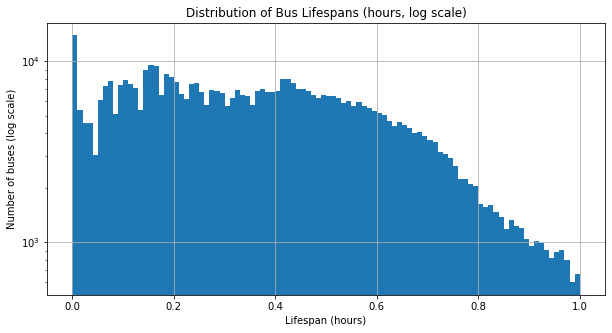

In [31]:
plt.figure(figsize=(10,5))
plt.hist(valid["duration_hours"], bins=100, log=True)
plt.title("Distribution of Bus Lifespans (hours, log scale)")
plt.xlabel("Lifespan (hours)")
plt.ylabel("Number of buses (log scale)")
plt.grid(True)
plt.show()

## 

# Archives
J'ai remplacés ces cellules par les miennes, mais elles pourraient encore servir

In [14]:
#Archivé
# --- 4. BUILD LOOKUP/Retrieve active schedule ---
print("Building GTFS lookup...")

#Get active service_ids
target_day_name = target_date_obj.strftime('%A').lower()
#calendar['start_date'] = pd.to_datetime(calendar['start_date'], format='%Y%m%d').dt.date
#calendar['end_date'] = pd.to_datetime(calendar['end_date'], format='%Y%m%d').dt.date
regular_services = calendar[(calendar[target_day_name] == 1) & (calendar['start_date'] <= target_date_obj) & (calendar['end_date'] >= target_date_obj)]
active_service_ids = set(regular_services['service_id'])
calendar_dates['date'] = pd.to_datetime(calendar_dates['date'], format='%Y%m%d').dt.date
date_exceptions = calendar_dates[calendar_dates['date'] == target_date_obj]
active_service_ids.update(date_exceptions[date_exceptions['exception_type'] == '1']['service_id'])
active_service_ids.difference_update(date_exceptions[date_exceptions['exception_type'] == '2']['service_id'])#'exception_type' est un string
active_services_df = pd.DataFrame(list(active_service_ids), columns=['service_id'])

#AUR: Pas utilisé ?
first_stops = stop_times.loc[stop_times.groupby('trip_id')['stop_sequence'].idxmin()]
trip_start_times = first_stops[['trip_id', 'departure_time']]

#%% Fusionne les stop_times actifs et les routes
trips_with_routes = trips.merge(routes[['route_id', 'route_short_name']], on='route_id')
#trips_with_routes['direction'] = trips_with_routes['direction_id'].astype(int) 
trips_with_routes['lineId'] = trips_with_routes['route_short_name'].astype(str).str.strip()#AUR: Inutile ?

gtfs_lookup = trips_with_routes.merge(active_services_df, on='service_id').merge(trip_start_times, on='trip_id')
gtfs_lookup['date'] = target_date_obj
gtfs_lookup['scheduled_departure_time'] = pd.to_datetime(gtfs_lookup['date'], format='%Y-%m-%d') + pd.to_timedelta(gtfs_lookup['departure_time'])
gtfs_lookup_final = gtfs_lookup[['trip_id', 'lineId', 'direction', 'date', 'scheduled_departure_time']]

Building GTFS lookup...


TypeError: Invalid comparison between dtype=datetime64[ns] and date

In [17]:
routes['lineId'] = routes['route_short_name'].astype(str).str.strip()
(routes['lineId']==routes['route_short_name']).all()

np.True_

In [9]:
print("Comparing with utils...")
active_stop_times, active_trips=utils.get_active_stop_times(target_date_obj, trips, stop_times, calendar, calendar_dates)
chk_merge=active_trips.merge(gtfs_lookup_final, on='trip_id',how='outer', indicator = True)
print(chk_merge.value_counts('_merge'))
diffs=chk_merge.query("_merge!='both'")
if(diffs.shape[0]!=0):
    print("Inconsistencies: ")
    print("Only in gtfs_lookup_final:")
    print(diffs.query("_merge=='right_only'")['service_id'])
    print("Only in active_trips:")
    print(diffs.query("_merge=='left_only'")['service_id'])
else:
    print("The active service_id's are coherent")

Comparing with utils...
_merge
both          19682
left_only         0
right_only        0
Name: count, dtype: int64
The active service_id's are coherent
